# 2. LSTM od zera

**Teoria do tego notebooka:** [`02_lstm.md`](02_lstm.md)

Plan:

1. komórka LSTM od zera + sprawdzenie z `torch.nn.LSTM`,
2. trening na "Panu Tadeuszu" i porównanie z RNN z rozdziału 1,
3. podgląd bramek: co LSTM "robi" na prawdziwym tekście,
4. przepływ gradientu: RNN vs LSTM, i dlaczego bias bramki zapominania = 1 ma znaczenie,
5. zadanie pamięciowe: o ile dalej sięga LSTM?

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from common import (MEMORY_VOCAB, count_params, load_results, plot_memory, prepare_data,
                    run_memory_experiment, sample_from_logits, save_results, set_seed, train,
                    TrainConfig)

plt.rcParams["figure.dpi"] = 110
tok, train_data, val_data = prepare_data()

## 1. Komórka LSTM

$$
\begin{aligned}
[i_t, f_t, g_t, o_t] &= x_t W_x + h_{t-1} W_h + b \quad \text{(jedno mnożenie, wynik tniemy na 4 części)}\\
c_t &= \sigma(f_t) \odot c_{t-1} + \sigma(i_t) \odot \tanh(g_t)\\
h_t &= \sigma(o_t) \odot \tanh(c_t)
\end{aligned}
$$

Kolejność bramek `i, f, g, o` jest taka sama jak w PyTorch, więc łatwo porównać wyniki.
Parametr `forget_bias` ustawia początkowy bias bramki zapominania (o tym w punkcie 4).

In [2]:
class LSTM(nn.Module):
    def __init__(self, input_size, hidden_size, forget_bias=1.0):
        super().__init__()
        H = hidden_size
        self.hidden_size = H
        bound = 1 / math.sqrt(H)
        self.W_x = nn.Parameter(torch.empty(input_size, 4 * H).uniform_(-bound, bound))
        self.W_h = nn.Parameter(torch.empty(H, 4 * H).uniform_(-bound, bound))
        b = torch.zeros(4 * H)
        b[H : 2 * H] = forget_bias
        self.b = nn.Parameter(b)

    def forward(self, x, state=None, return_gates=False):
        """x: (B, T, input_size) -> (wszystkie h (B, T, H), (h_T, c_T)) [+ słownik bramek do wizualizacji]."""
        B, H = x.shape[0], self.hidden_size
        h, c = (x.new_zeros(B, H), x.new_zeros(B, H)) if state is None else state
        hs, gates_log = [], {"f": [], "i": [], "o": [], "c": []}
        for xw_t in (x @ self.W_x + self.b).unbind(dim=1):
            i, f, g, o = (xw_t + h @ self.W_h).chunk(4, dim=-1)
            i, f, o, g = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o), torch.tanh(g)
            c = f * c + i * g
            h = o * torch.tanh(c)
            hs.append(h)
            if return_gates:
                for name, val in zip("fioc", (f, i, o, c)):
                    gates_log[name].append(val)
        out = (torch.stack(hs, dim=1), (h, c))
        if return_gates:
            return out + ({k: torch.stack(v, dim=1) for k, v in gates_log.items()},)
        return out


set_seed(0)
ref = nn.LSTM(input_size=8, hidden_size=16, batch_first=True)
ours = LSTM(8, 16)
with torch.no_grad():
    ours.W_x.copy_(ref.weight_ih_l0.T)
    ours.W_h.copy_(ref.weight_hh_l0.T)
    ours.b.copy_(ref.bias_ih_l0 + ref.bias_hh_l0)
x = torch.randn(4, 10, 8)
print("max różnica wyjść względem nn.LSTM:", (ours(x)[0] - ref(x)[0]).abs().max().item())

max różnica wyjść względem nn.LSTM: 8.940696716308594e-08


## 2. Znakowy model języka na LSTM

In [3]:
class CharLSTM(nn.Module):
    def __init__(self, vocab_size, emb_dim=64, hidden_size=320, forget_bias=1.0):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim)
        self.lstm = LSTM(emb_dim, hidden_size, forget_bias)
        self.head = nn.Linear(hidden_size, vocab_size)

    def forward(self, idx, state=None, return_state=False):
        out, state = self.lstm(self.emb(idx), state)
        logits = self.head(out)
        return (logits, state) if return_state else logits


set_seed(1337)
model = CharLSTM(tok.vocab_size)
print(f"parametry: {count_params(model):,}".replace(",", " "), "(4 zestawy wag zamiast jednego)")

parametry: 526 295 (4 zestawy wag zamiast jednego)


In [4]:
cfg = TrainConfig(lr=8e-3)
hist = train(model, train_data, val_data, cfg)

krok     0 | train   -   | val 4.456 |    0.0s


krok   100 | train 2.941 | val 2.329 |   10.4s


krok   200 | train 2.161 | val 2.083 |   20.7s


krok   300 | train 1.969 | val 1.962 |   31.0s


krok   400 | train 1.868 | val 1.896 |   41.8s


...

krok   600 | train 1.743 | val 1.816 |   62.4s


krok   700 | train 1.703 | val 1.794 |   72.6s


krok   800 | train 1.676 | val 1.775 |   83.2s


krok   900 | train 1.654 | val 1.765 |   93.7s


krok  1000 | train 1.634 | val 1.761 |  104.1s


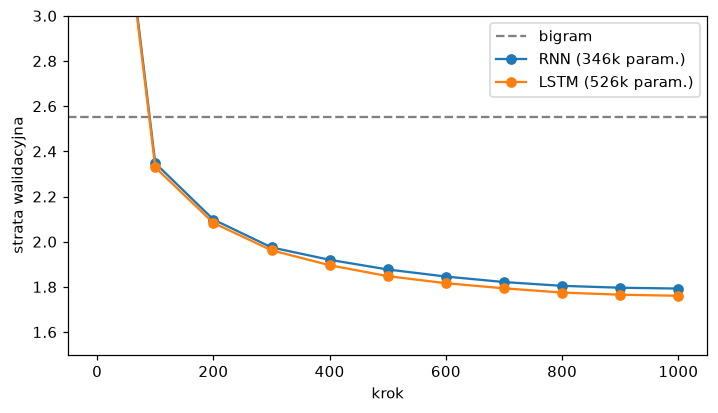

LSTM: 1.761 (104 ms/krok) | RNN: 1.792 (57 ms/krok)


In [5]:
rnn = load_results("01_rnn")
bigram = load_results("00_bigram")
fig, ax = plt.subplots(figsize=(7.5, 4))
if bigram:
    ax.axhline(bigram["val_loss"][-1], color="gray", ls="--", label="bigram")
if rnn:
    ax.plot(rnn["eval_step"], rnn["val_loss"], "o-", label=f"RNN ({rnn['n_params'] / 1e3:.0f}k param.)")
ax.plot(hist["eval_step"], hist["val_loss"], "o-", label=f"LSTM ({hist['n_params'] / 1e3:.0f}k param.)")
ax.set_ylim(1.5, 3.0)
ax.set_xlabel("krok")
ax.set_ylabel("strata walidacyjna")
ax.legend()
plt.show()
print(f"LSTM: {hist['val_loss'][-1]:.3f} ({hist['sec_per_step'] * 1000:.0f} ms/krok)", end="")
if rnn:
    print(f" | RNN: {rnn['val_loss'][-1]:.3f} ({rnn['sec_per_step'] * 1000:.0f} ms/krok)")

LSTM wypada lepiej niż RNN, ale różnica w stracie jest niewielka. Na **znakowym** modelowaniu języka z krótkim oknem
większość informacji potrzebnej do przewidzenia następnej litery jest w ostatnich kilkunastu znakach, a tam RNN
jeszcze "widzi". Wyraźna przewaga LSTM ujawnia się przy **dalekich** zależnościach (punkt 5).
Zwróć też uwagę na czas: LSTM liczy 4× więcej w każdym kroku pętli. Do tego LSTM lubi wysoki learning rate
(tu 8e-3; przy 2e-3 kończył z wyraźnie gorszą stratą).

In [6]:
@torch.no_grad()
def generate_lstm(model, prompt, n_new, temperature=0.8, seed=0):
    model.eval()
    g = torch.Generator().manual_seed(seed)
    idx = torch.tensor([tok.encode(prompt)])
    logits, state = model(idx, return_state=True)
    out = idx[0].tolist()
    for _ in range(n_new):
        nxt = sample_from_logits(logits[:, -1], temperature, generator=g)
        out.append(nxt.item())
        logits, state = model(nxt, state, return_state=True)
    model.train()
    return tok.decode(out)


sample = generate_lstm(model, "Litwo! Ojczyzno moja! ", 400)
print(sample)
save_results("02_lstm", {"name": "LSTM", **hist, "sample": sample})

Litwo! Ojczyzno moja! to za składę,
Przyszła ogania napierał w woli w jeździa.
To też mu broń w tej mój łowie.

Zaściancuza wspomodą dawniej nie sławie,
I był Sędzia na ziemi gromu Dobrzyńskiej spokruta
Nog nie wyszli z człek ważnych szyję przy niecię!
Opstwie, że w górymi ludźmi szczernę —
To ten narzecz odcież tylko ścisnął się dragi
I te pan jednej skiera!
Teraz był z kroku za wielkiej wzgładza od mieszka.
Zaś w klę


PosixPath('/home/womackow/CODE_SPACE/agh/sem2/UMISI-sem2-NN-Arch/RWKV/results/02_lstm.json')

## 3. Co robią bramki?

Puszczamy kawałek tekstu przez wytrenowany LSTM i porównujemy dwie grupy jednostek:
4 "szybkie" (bramka zapominania zmienia się najbardziej) i 4 "wolne" (średnia wartość $f_t$ najbliższa 1).
Oś pozioma to kolejne znaki (⏎ = nowa linia). Stan komórki normalizujemy osobno dla każdej jednostki.

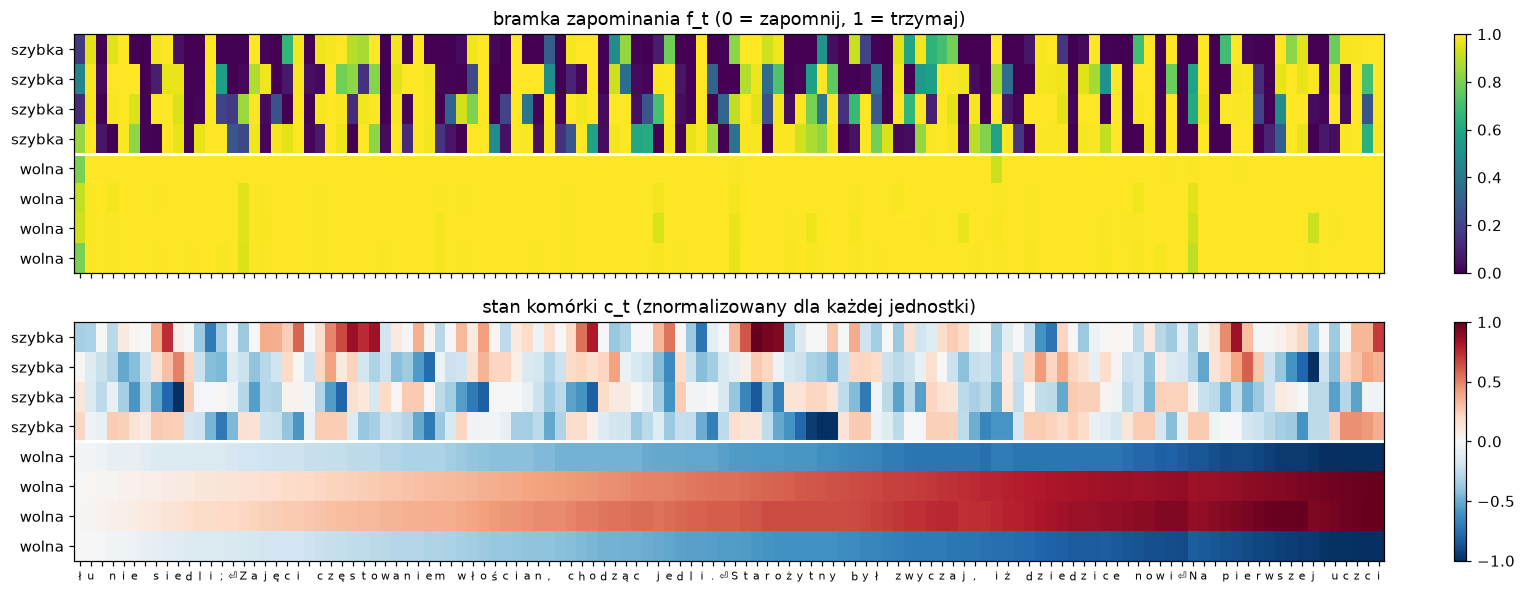

średnie f_t:  szybkie [0.45, 0.51, 0.59, 0.59] | wolne [0.997, 0.997, 0.995, 0.994]


In [7]:
snippet = val_data[2000:2120]
with torch.no_grad():
    _, _, gates = model.lstm(model.emb(snippet[None]), return_gates=True)
f, c = gates["f"][0], gates["c"][0]
fast, slow = f.std(0).topk(4).indices, f.mean(0).topk(4).indices
units = torch.cat([fast, slow])
c_norm = c[:, units] / c[:, units].abs().max(0).values

fig, axes = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True)
im = axes[0].imshow(f[:, units].T, aspect="auto", cmap="viridis", vmin=0, vmax=1)
axes[0].set_title("bramka zapominania f_t (0 = zapomnij, 1 = trzymaj)")
fig.colorbar(im, ax=axes[0], fraction=0.02)
im = axes[1].imshow(c_norm.T, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_title("stan komórki c_t (znormalizowany dla każdej jednostki)")
fig.colorbar(im, ax=axes[1], fraction=0.02)
for ax in axes:
    ax.axhline(3.5, color="white", lw=2)
    ax.set_yticks(range(8), ["szybka"] * 4 + ["wolna"] * 4)
chars = tok.decode(snippet).replace("\n", "⏎")
axes[1].set_xticks(range(len(chars)), list(chars), fontsize=7)
plt.tight_layout()
plt.show()
print("średnie f_t:  szybkie", [round(v, 2) for v in f[:, fast].mean(0).tolist()],
      "| wolne", [round(v, 3) for v in f[:, slow].mean(0).tolist()])

- **Szybkie** jednostki przełączają bramkę zapominania niemal z każdym znakiem: to pamięć krótka
  ("co było przed chwilą"), jej stan co chwilę jest kasowany i zapisywany od nowa.
- **Wolne** jednostki trzymają $f_t \approx 1$ przez cały fragment, a ich stan zmienia się powoli: to pamięć długa
  i zarazem "autostrada" dla gradientu.

LSTM sam uczy się jednostek o **różnych skalach czasowych**. Zapamiętaj ten obraz: RWKV (rozdział 4) robi to samo
jawnie, bo każdy kanał ma własny, uczony zanik $w$ niezależny od danych.

## 4. Przepływ gradientu: RNN vs LSTM

Ten sam pomiar co w rozdziale 1: jak mocno stan końcowy zależy od wejścia sprzed $n$ kroków, dla świeżo
zainicjalizowanych sieci. Porównujemy RNN, LSTM z biasem bramki zapominania 0 (domyślnie w PyTorch)
i LSTM z biasem 1.

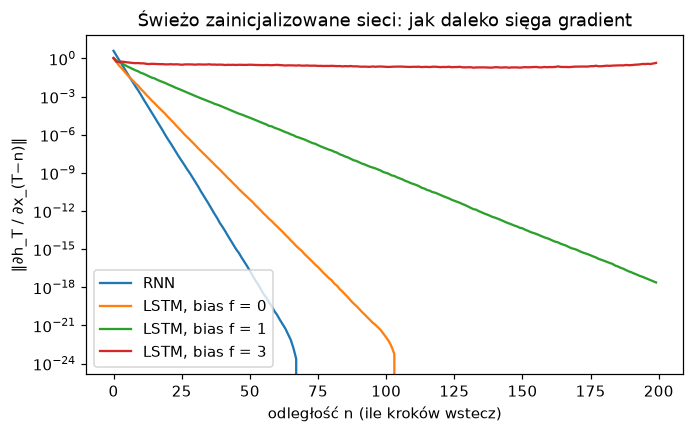

In [8]:
class RNNCell(nn.Module):
    """Minimalny RNN do porównania (taki sam jak w rozdziale 1)."""

    def __init__(self, n_in, n_hidden):
        super().__init__()
        self.hidden_size = n_hidden
        bound = 1 / math.sqrt(n_hidden)
        self.W_xh = nn.Parameter(torch.empty(n_in, n_hidden).uniform_(-bound, bound))
        self.W_hh = nn.Parameter(torch.empty(n_hidden, n_hidden).uniform_(-bound, bound))
        self.b = nn.Parameter(torch.zeros(n_hidden))

    def forward(self, x):
        h = x.new_zeros(x.shape[0], self.hidden_size)
        for xw_t in (x @ self.W_xh + self.b).unbind(1):
            h = torch.tanh(xw_t + h @ self.W_hh)
        return None, h


def final_state_gradients(net, x):
    x = x.clone().requires_grad_(True)
    _, last = net(x)
    h_T = last[0] if isinstance(last, tuple) else last
    (h_T * torch.randn_like(h_T, generator=torch.Generator().manual_seed(0))).sum().backward()
    return x.grad.norm(dim=-1).mean(0).flip(0)


T, H = 200, 64
x = torch.randn(16, T, H, generator=torch.Generator().manual_seed(1))
curves = {}
for name, make in [("RNN", lambda: RNNCell(H, H)),
                   ("LSTM, bias f = 0", lambda: LSTM(H, H, forget_bias=0.0)),
                   ("LSTM, bias f = 1", lambda: LSTM(H, H, forget_bias=1.0)),
                   ("LSTM, bias f = 3", lambda: LSTM(H, H, forget_bias=3.0))]:
    set_seed(0)
    curves[name] = final_state_gradients(make(), x)

fig, ax = plt.subplots(figsize=(7, 4))
for name, g in curves.items():
    ax.semilogy(range(T), g.detach(), label=name)
ax.set_xlabel("odległość n (ile kroków wstecz)")
ax.set_ylabel("‖∂h_T / ∂x_(T−n)‖")
ax.set_title("Świeżo zainicjalizowane sieci: jak daleko sięga gradient")
ax.legend()
plt.show()

- RNN: gradient spada wykładniczo i bardzo szybko.
- LSTM z biasem 0: bramka zapominania startuje w okolicach $\sigma(0) = 0{,}5$, więc pamięć też szybko gaśnie
  ($0{,}5^n$).
- LSTM z biasem 1 lub 3: $f \approx 0{,}73$ lub $0{,}95$ na starcie, więc sygnał żyje o wiele dłużej.
  Dlatego Gers i in. (2000) oraz Jozefowicz i in. (2015) zalecają dodatni bias bramki zapominania:
  sieć **zaczyna** od "pamiętaj", a uczy się zapominać tam, gdzie trzeba.

## 5. Zadanie pamięciowe: LSTM vs RNN

Protokół jak w rozdziale 1 (świeży model na każdą odległość, 2 seedy, limit 1000 kroków z wczesnym
zatrzymaniem). Dla szybkości `nn.LSTM`, który liczy to samo co nasza klasa (sprawdzone w punkcie 1).
Porównujemy dwa biasy bramki zapominania: standardowe 1 i "odważniejsze" 3 ($\sigma(3) \approx 0{,}95$).

In [9]:
class TorchCharLSTM(nn.Module):
    """CharLSTM z nn.LSTM zamiast pętli w Pythonie; forget_bias ustawiamy ręcznie (PyTorch ma dwa biasy na bramkę)."""

    def __init__(self, vocab_size, emb_dim=32, hidden_size=128, forget_bias=1.0):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim)
        self.lstm = nn.LSTM(emb_dim, hidden_size, batch_first=True)
        with torch.no_grad():
            self.lstm.bias_ih_l0[hidden_size : 2 * hidden_size].fill_(forget_bias)
            self.lstm.bias_hh_l0[hidden_size : 2 * hidden_size].zero_()
        self.head = nn.Linear(hidden_size, vocab_size)

    def forward(self, idx):
        return self.head(self.lstm(self.emb(idx))[0])


MEMORY_LENGTHS = [5, 10, 20, 40, 80]
print("LSTM, bias bramki zapominania = 1")
memory_fb1 = run_memory_experiment(lambda: TorchCharLSTM(MEMORY_VOCAB, forget_bias=1.0), MEMORY_LENGTHS,
                                   name="LSTM (bias f = 1)")
print("LSTM, bias bramki zapominania = 3")
memory_fb3 = run_memory_experiment(lambda: TorchCharLSTM(MEMORY_VOCAB, forget_bias=3.0), MEMORY_LENGTHS,
                                   name="LSTM (bias f = 3)")
save_results("02_lstm_memory", memory_fb1)
save_results("02_lstm_memory_fb3", memory_fb3)

LSTM, bias bramki zapominania = 1


L =    5: trafność 100% / 100%   kroki treningu:   63 /   63   (0 s)


L =   10: trafność 100% / 100%   kroki treningu:   85 /   80   (0 s)


L =   20: trafność  36% / 100%   kroki treningu: 1000 /  835   (7 s)


L =   40: trafność  11% /  12%   kroki treningu: 1000 / 1000   (14 s)


...

L =   10: trafność 100% / 100%   kroki treningu:   61 /   58   (0 s)


L =   20: trafność 100% / 100%   kroki treningu:   65 /   60   (1 s)


L =   40: trafność 100% / 100%   kroki treningu:   91 /   76   (1 s)


L =   80: trafność  15% /  13%   kroki treningu: 1000 / 1000   (39 s)


PosixPath('/home/womackow/CODE_SPACE/agh/sem2/UMISI-sem2-NN-Arch/RWKV/results/02_lstm_memory_fb3.json')

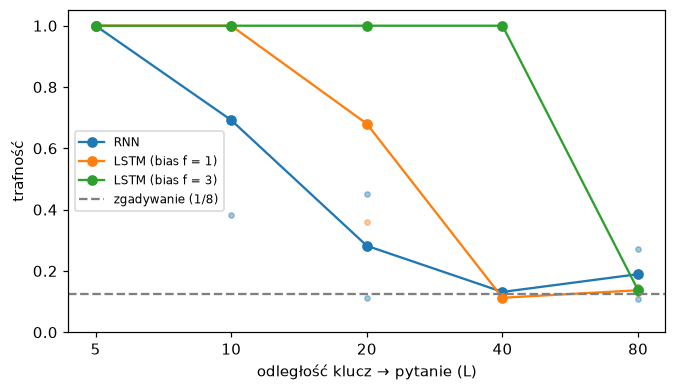

In [10]:
plot_memory([load_results("01_rnn_memory"), memory_fb1, memory_fb3])
plt.show()

- LSTM sięga dalej niż RNN i robi to stabilnie (oba seedy zgodne).
- Bias bramki zapominania przesuwa granicę: z biasem 3 zadanie przy $L = 40$ rozwiązuje się w kilkadziesiąt kroków,
  z biasem 1 trzeba na to setek kroków albo się nie udaje. To jest wykres z punktu 4 przełożony na wynik.
- Przy $L = 80$ oba warianty przegrywają w tym budżecie: sygnał $\approx f^{L}$ jest wciąż za słaby, żeby trening
  go znalazł. LSTM pomaga, ale nie usuwa problemu: informacja dalej musi przejść przez $L$ kroków rekurencji.

## Podsumowanie

- LSTM to RNN z addytywnym stanem komórki i trzema bramkami. Kod to ~20 linii więcej niż RNN.
- Na krótkich zależnościach (litery w słowie) zysk względem RNN jest mały, za to każdy krok pętli liczy 4× więcej
  (u nas krok treningu trwa ok. 2× dłużej).
- Na **dalekich** zależnościach LSTM sięga znacznie dalej. Kluczowy jest bias bramki zapominania.
- Pętla po czasie i stan o stałym rozmiarze zostają. Następny krok w historii to pozbycie się pętli: Transformer.

**Dalej:** [`03_transformer.md`](03_transformer.md) → [`03_transformer.ipynb`](03_transformer.ipynb)